### Customer Churn Prediction — Preprocessing & Feature Engineering Pipeline

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import (LabelEncoder, OneHotEncoder, OrdinalEncoder,
                                   StandardScaler, MinMaxScaler, FunctionTransformer)
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.feature_selection import mutual_info_classif, SelectKBest, f_classif
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (classification_report, confusion_matrix, roc_auc_score,
                             ConfusionMatrixDisplay, RocCurveDisplay)
import joblib

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")
os.makedirs("images", exist_ok=True)   # plots are saved here for the README / report
RANDOM_STATE = 42
print("Setup complete")

c:\Users\93802\anaconda3\Lib\site-packages\pandas\core\computation\expressions.py:22: UserWarning: Pandas requires version '2.11.0' or newer of 'numexpr' (version '2.10.1' currently installed).
  from pandas.core.computation.check import (
c:\Users\93802\anaconda3\Lib\site-packages\pandas\core\arrays\masked.py:63: UserWarning: Pandas requires version '1.5.0' or newer of 'bottleneck' (version '1.4.2' currently installed).
  from pandas.core import (


Setup complete


## Explore & Understand the Data

In [2]:
df = pd.read_csv("churn_data.csv")
print("Shape:", df.shape)
df.head()

Shape: (500, 9)


,CustomerID,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,Churn
0,C00001,6,64,1540,One year,Credit Card,No,1,0
1,C00002,21,113,1753,Month-to-month,Electronic Check,Yes,1,0
2,C00003,27,31,1455,Two year,Credit Card,No,1,0
3,C00004,53,29,7150,Month-to-month,Electronic Check,No,1,0
4,C00005,16,185,1023,One year,Electronic Check,No,1,0


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   CustomerID        500 non-null    str  
 1   Tenure            500 non-null    int64
 2   MonthlyCharges    500 non-null    int64
 3   TotalCharges      500 non-null    int64
 4   Contract          500 non-null    str  
 5   PaymentMethod     500 non-null    str  
 6   PaperlessBilling  500 non-null    str  
 7   SeniorCitizen     500 non-null    int64
 8   Churn             500 non-null    int64
dtypes: int64(5), str(4)
memory usage: 50.8 KB


In [4]:
print("Missing values per column:\n", df.isnull().sum())
print("\nDuplicate CustomerIDs:", df["CustomerID"].duplicated().sum())
df.describe()

Missing values per column:
 CustomerID          0
Tenure              0
MonthlyCharges      0
TotalCharges        0
Contract            0
PaymentMethod       0
PaperlessBilling    0
SeniorCitizen       0
Churn               0
dtype: int64

Duplicate CustomerIDs: 0


,Tenure,MonthlyCharges,TotalCharges,SeniorCitizen,Churn
count,500.000000,500.000000,500.000000,500.000000,500.000000
mean,36.532000,113.636000,4237.882000,0.498000,0.106000
std,20.667057,51.799903,2260.619837,0.500497,0.308146
min,1.000000,20.000000,159.000000,0.000000,0.000000
25%,19.000000,67.000000,2237.250000,0.000000,0.000000
50%,37.000000,115.000000,4182.500000,0.000000,0.000000
75%,54.000000,158.000000,6266.750000,1.000000,0.000000
max,71.000000,199.000000,7992.000000,1.000000,1.000000


Churn
0    447
1     53
Name: count, dtype: int64

Churn rate: 10.6%


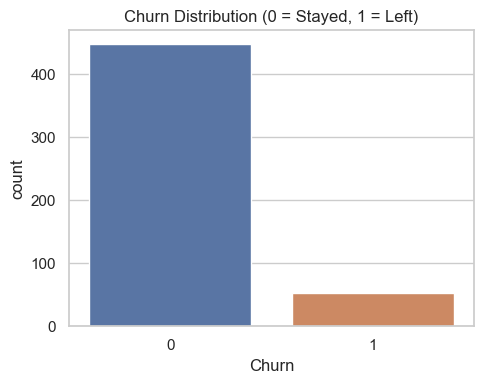

In [5]:
# Churn distribution (target)
print(df["Churn"].value_counts())
print("\nChurn rate: {:.1%}".format(df["Churn"].mean()))

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(x="Churn", data=df, ax=ax, palette=["#4C72B0", "#DD8452"])
ax.set_title("Churn Distribution (0 = Stayed, 1 = Left)")
plt.tight_layout(); plt.savefig("images/01_churn_distribution.png", dpi=120); plt.show()

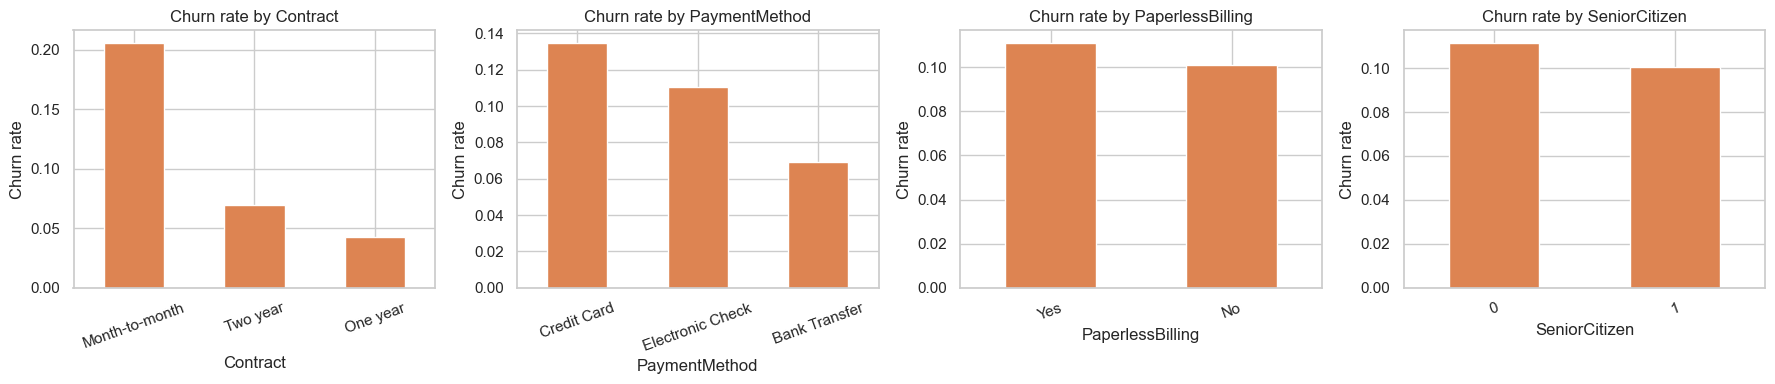

                count   mean
Contract                    
Month-to-month    170  0.206
One year          186  0.043
Two year          144  0.069 

                  count   mean
PaymentMethod                 
Bank Transfer       159  0.069
Credit Card         178  0.135
Electronic Check    163  0.110 

                  count   mean
PaperlessBilling              
No                  257  0.101
Yes                 243  0.111 

               count   mean
SeniorCitizen              
0                251  0.112
1                249  0.100 



In [6]:
# Churn rate by each categorical column
cat_cols = ["Contract", "PaymentMethod", "PaperlessBilling", "SeniorCitizen"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes, cat_cols):
    rate = df.groupby(col)["Churn"].mean().sort_values(ascending=False)
    rate.plot(kind="bar", ax=ax, color="#DD8452")
    ax.set_title(f"Churn rate by {col}"); ax.set_ylabel("Churn rate"); ax.tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.savefig("images/02_churn_by_category.png", dpi=120); plt.show()

for col in cat_cols:
    print(df.groupby(col)["Churn"].agg(["count", "mean"]).round(3), "\n")

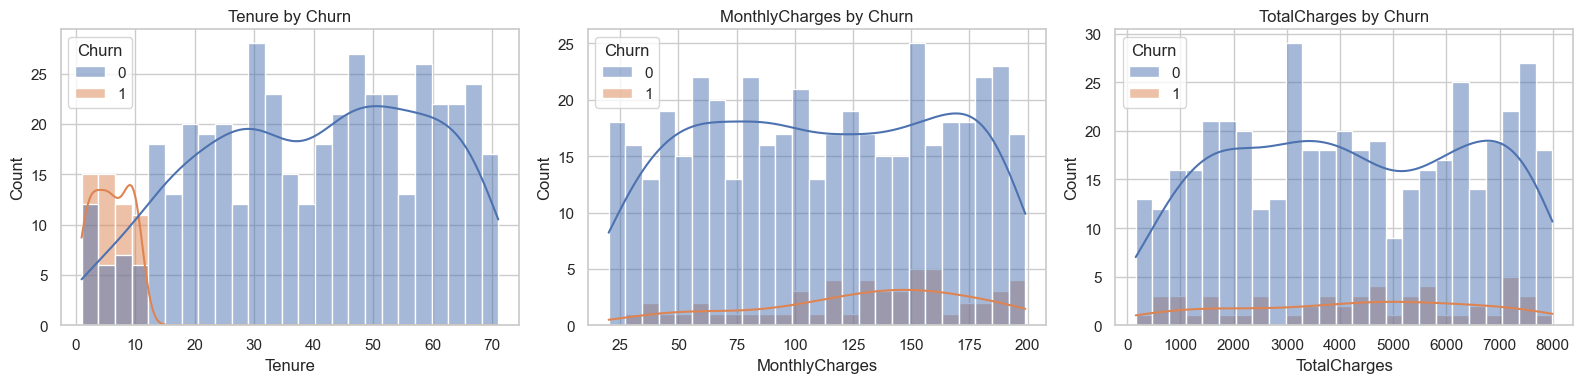

,Tenure,MonthlyCharges,TotalCharges
Churn,,,
0,40.2,111.7,4234.6
1,6.0,129.8,4265.8


In [7]:
# Numeric distributions split by churn
num_cols = ["Tenure", "MonthlyCharges", "TotalCharges"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Churn", kde=True, ax=ax, bins=25)
    ax.set_title(f"{col} by Churn")
plt.tight_layout(); plt.savefig("images/03_numeric_distributions.png", dpi=120); plt.show()

df.groupby("Churn")[num_cols].mean().round(1)

## Handle Categorical Data (4 encoding methods)

In [10]:
df_enc = df.copy()

# LABEL ENCODING — binary Yes/No column -> 0/1
le = LabelEncoder()
df_enc["PaperlessBilling_le"] = le.fit_transform(df_enc["PaperlessBilling"])
print("1) Label Encoding mapping:", dict(zip(le.classes_, le.transform(le.classes_))))

# ORDINAL ENCODING — Contract has a natural order (short -> long commitment)
contract_order = [["Month-to-month", "One year", "Two year"]]
oe = OrdinalEncoder(categories=contract_order)
df_enc["Contract_ord"] = oe.fit_transform(df_enc[["Contract"]]).astype(int)
print("2) Ordinal Encoding mapping:", {c: i for i, c in enumerate(contract_order[0])})

# ONE-HOT ENCODING — PaymentMethod has no order
ohe = OneHotEncoder(sparse_output=False, drop="first")
ohe_arr = ohe.fit_transform(df_enc[["PaymentMethod"]])
ohe_cols = ohe.get_feature_names_out(["PaymentMethod"])
df_enc[ohe_cols] = ohe_arr.astype(int)
print("3) One-Hot columns created:", list(ohe_cols), "(dropped first to avoid dummy trap)")

# FREQUENCY ENCODING — replace category with how often it appears
freq_map = df_enc["PaymentMethod"].value_counts(normalize=True)
df_enc["PaymentMethod_freq"] = df_enc["PaymentMethod"].map(freq_map).round(3)
print("4) Frequency Encoding mapping:", freq_map.round(3).to_dict())

df_enc[["Contract", "Contract_ord", "PaymentMethod", *ohe_cols, "PaymentMethod_freq",
        "PaperlessBilling", "PaperlessBilling_le"]].head(8)

1) Label Encoding mapping: {'No': np.int64(0), 'Yes': np.int64(1)}
2) Ordinal Encoding mapping: {'Month-to-month': 0, 'One year': 1, 'Two year': 2}
3) One-Hot columns created: ['PaymentMethod_Credit Card', 'PaymentMethod_Electronic Check'] (dropped first to avoid dummy trap)
4) Frequency Encoding mapping: {'Credit Card': 0.356, 'Electronic Check': 0.326, 'Bank Transfer': 0.318}


,Contract,Contract_ord,PaymentMethod,PaymentMethod_Credit Card,PaymentMethod_Electronic Check,PaymentMethod_freq,PaperlessBilling,PaperlessBilling_le
0,One year,1,Credit Card,1,0,0.356,No,0
1,Month-to-month,0,Electronic Check,0,1,0.326,Yes,1
2,Two year,2,Credit Card,1,0,0.356,No,0
3,Month-to-month,0,Electronic Check,0,1,0.326,No,0
4,One year,1,Electronic Check,0,1,0.326,No,0
5,Two year,2,Electronic Check,0,1,0.326,No,0
6,Two year,2,Bank Transfer,0,0,0.318,No,0
7,Month-to-month,0,Bank Transfer,0,0,0.318,No,0


In [11]:
# Bonus comparison: pandas get_dummies (quick one-hot) vs sklearn OneHotEncoder
pd.get_dummies(df["Contract"], prefix="Contract", dtype=int).head()

,Contract_Month-to-month,Contract_One year,Contract_Two year
0,0,1,0
1,1,0,0
2,0,0,1
3,1,0,0
4,0,1,0


###  Feature Scaling (Min-Max vs Standard)

In [12]:
scale_cols = ["Tenure", "MonthlyCharges", "TotalCharges"]

mm = MinMaxScaler()
ss = StandardScaler()
df_minmax = pd.DataFrame(mm.fit_transform(df[scale_cols]), columns=scale_cols)
df_std    = pd.DataFrame(ss.fit_transform(df[scale_cols]), columns=scale_cols)

summary = pd.concat({
    "Original": df[scale_cols].agg(["min", "max", "mean", "std"]),
    "MinMax":   df_minmax.agg(["min", "max", "mean", "std"]),
    "Standard": df_std.agg(["min", "max", "mean", "std"]),
}).round(3)
summary

Tenure  MonthlyCharges  TotalCharges
Original min    1.000          20.000       159.000
         max   71.000         199.000      7992.000
         mean  36.532         113.636      4237.882
         std   20.667          51.800      2260.620
MinMax   min    0.000           0.000         0.000
         max    1.000           1.000         1.000
         mean   0.508           0.523         0.521
         std    0.295           0.289         0.289
Standard min   -1.721          -1.809        -1.806
         max    1.669           1.650         1.662
         mean   0.000           0.000         0.000
         std    1.001           1.001         1.001

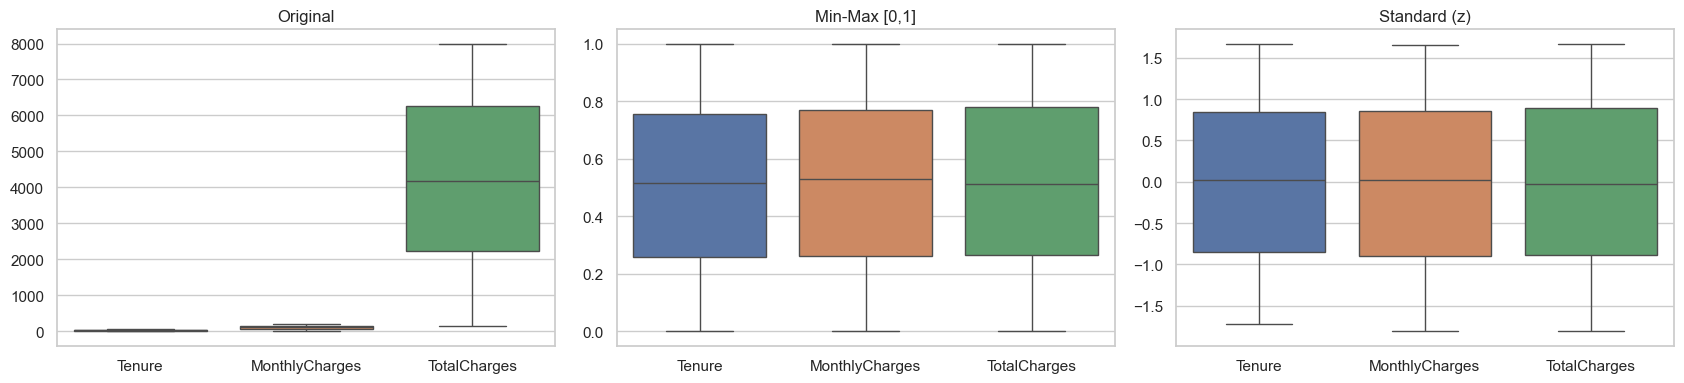

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, (name, data) in zip(axes, [("Original", df[scale_cols]), ("Min-Max [0,1]", df_minmax), ("Standard (z)", df_std)]):
    sns.boxplot(data=data, ax=ax); ax.set_title(name)
plt.tight_layout(); plt.savefig("images/04_scaling_comparison.png", dpi=120); plt.show()

In [14]:
# Effect of scaling on a distance/gradient-based model (Logistic Regression)
X_raw = df[scale_cols]; y = df["Churn"]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
for name, scaler in [("No scaling", None), ("MinMax", MinMaxScaler()), ("Standard", StandardScaler())]:
    steps = ([("scaler", scaler)] if scaler else []) + [("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))]
    auc = cross_val_score(Pipeline(steps), X_raw, y, cv=cv, scoring="roc_auc")
    print(f"{name:<11} ROC-AUC = {auc.mean():.3f} ± {auc.std():.3f}")

No scaling  ROC-AUC = 0.970 ± 0.015
MinMax      ROC-AUC = 0.970 ± 0.014
Standard    ROC-AUC = 0.970 ± 0.014


## Outlier Detection & Handling (IQR + Z-score)

In [15]:
def iqr_outliers(s, k=1.5):
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    low, high = q1 - k * iqr, q3 + k * iqr
    return (s < low) | (s > high), low, high

rows = []
for col in scale_cols:
    mask_iqr, low, high = iqr_outliers(df[col])
    z = np.abs(stats.zscore(df[col]))
    rows.append({"Feature": col, "Q1": df[col].quantile(.25), "Q3": df[col].quantile(.75),
                 "IQR_low": round(low, 1), "IQR_high": round(high, 1),
                 "IQR_outliers": int(mask_iqr.sum()), "Z>3_outliers": int((z > 3).sum()),
                 "Max |z|": round(z.max(), 2)})
outlier_report = pd.DataFrame(rows)
outlier_report

,Feature,Q1,Q3,IQR_low,IQR_high,IQR_outliers,Z>3_outliers,Max |z|
0,Tenure,19.00,54.00,-33.5,106.5,0,0,1.72
1,MonthlyCharges,67.00,158.00,-69.5,294.5,0,0,1.81
2,TotalCharges,2237.25,6266.75,-3807.0,12311.0,0,0,1.81


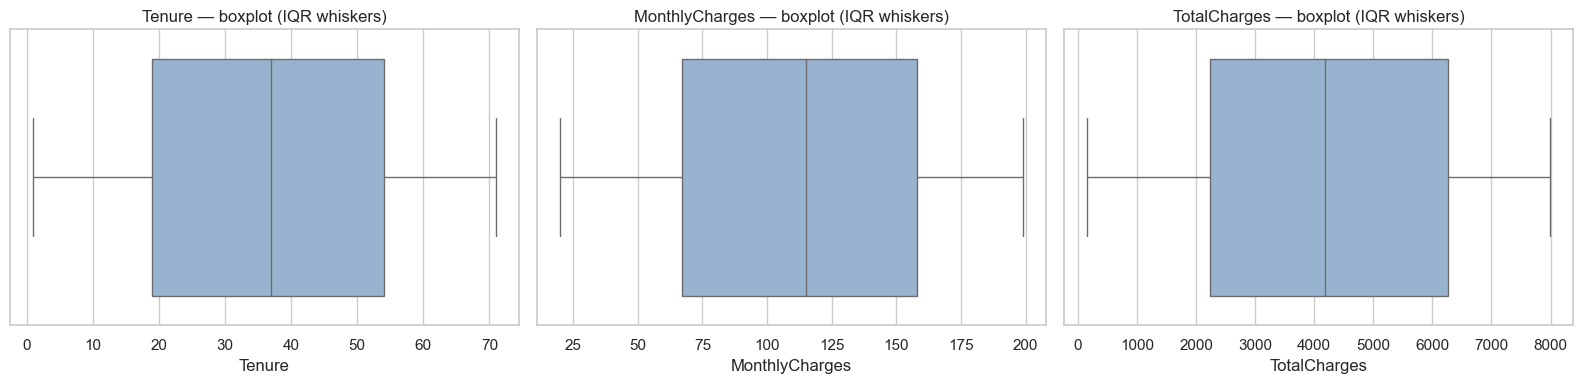

In [16]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, scale_cols):
    sns.boxplot(x=df[col], ax=ax, color="#8fb3d9"); ax.set_title(f"{col} — boxplot (IQR whiskers)")
plt.tight_layout(); plt.savefig("images/05_outlier_boxplots.png", dpi=120); plt.show()

In [ ]:
class IQRCapper(BaseEstimator, TransformerMixin):
    def __init__(self, k=1.5):
        self.k = k
    def fit(self, X, y=None):
        X = pd.DataFrame(X)
        q1, q3 = X.quantile(0.25), X.quantile(0.75)
        iqr = q3 - q1
        self.low_, self.high_ = q1 - self.k * iqr, q3 + self.k * iqr
        return self
    def transform(self, X):
        return pd.DataFrame(X).clip(self.low_, self.high_, axis=1)
    def get_feature_names_out(self, input_features=None):
        return np.asarray(input_features if input_features is not None else self.low_.index, dtype=object)

# Demo on data with an injected extreme value to show it works
demo = df[scale_cols].copy()
demo.loc[0, "MonthlyCharges"] = 999
capped = IQRCapper().fit(df[scale_cols]).transform(demo)
print("Before capping:", demo.loc[0, "MonthlyCharges"], "→ after capping:", capped.loc[0, "MonthlyCharges"])

Before capping: 999 → after capping: 294.5


### Feature Engineering:: 8 new features

In [19]:
class FeatureEngineer(BaseEstimator, TransformerMixin):
    """Creates new features from the raw columns. Stateless -> safe in a pipeline."""
    def fit(self, X, y=None):
        return self

    def transform(self, X):
        X = X.copy()
        contract_months = X["Contract"].map({"Month-to-month": 1, "One year": 12, "Two year": 24})

        # 1. Customer Lifetime Value: what they *would* pay at current rate over their tenure
        X["CLV"] = X["Tenure"] * X["MonthlyCharges"]
        # 2. Average monthly spend actually billed
        X["AvgMonthlySpend"] = X["TotalCharges"] / X["Tenure"].clip(lower=1)
        # 3. Payment Efficiency: actual billed vs expected (≈1 = pays as expected)
        X["PaymentEfficiency"] = X["TotalCharges"] / X["CLV"].clip(lower=1)
        # 4. Charge-to-tenure ratio: high monthly bill for a new customer = risk
        X["ChargePerTenure"] = X["MonthlyCharges"] / X["Tenure"].clip(lower=1)
        # 5. Is the customer new (first year)?
        X["IsNewCustomer"] = (X["Tenure"] <= 12).astype(int)
        # 6. Tenure group (binned)
        X["TenureGroup"] = pd.cut(X["Tenure"], bins=[0, 12, 24, 48, 100],
                                  labels=["0-1yr", "1-2yr", "2-4yr", "4+yr"]).astype(str)
        # 7. Automatic payment (bank transfer / credit card) vs manual electronic check
        X["AutoPay"] = X["PaymentMethod"].isin(["Bank Transfer", "Credit Card"]).astype(int)
        # 8. Contract commitment remaining relative to tenure
        X["ContractToTenure"] = contract_months / X["Tenure"].clip(lower=1)
        # 9. High-value monthly plan flag (above ~median of 110)
        X["HighMonthlyCharge"] = (X["MonthlyCharges"] > 110).astype(int)
        return X

fe = FeatureEngineer()
df_fe = fe.fit_transform(df)
new_features = ["CLV", "AvgMonthlySpend", "PaymentEfficiency", "ChargePerTenure", "IsNewCustomer",
                "TenureGroup", "AutoPay", "ContractToTenure", "HighMonthlyCharge"]
print(f"Created {len(new_features)} new features")
df_fe[["Tenure", "MonthlyCharges", "TotalCharges", *new_features]].head()

Created 9 new features


,Tenure,MonthlyCharges,TotalCharges,CLV,AvgMonthlySpend,PaymentEfficiency,ChargePerTenure,IsNewCustomer,TenureGroup,AutoPay,ContractToTenure,HighMonthlyCharge
0,6,64,1540,384,256.666667,4.010417,10.666667,1,0-1yr,1,2.000000,0
1,21,113,1753,2373,83.476190,0.738727,5.380952,0,1-2yr,0,0.047619,1
2,27,31,1455,837,53.888889,1.738351,1.148148,0,2-4yr,1,0.888889,0
3,53,29,7150,1537,134.905660,4.651919,0.547170,0,4+yr,0,0.018868,0
4,16,185,1023,2960,63.937500,0.345608,11.562500,0,1-2yr,0,0.750000,1


In [20]:
# How well does each new numeric feature separate churners vs non-churners?
num_new = [f for f in new_features if f != "TenureGroup"]
df_fe.groupby("Churn")[num_new].mean().T.round(3)

Churn,0,1
CLV,4479.215,784.868
AvgMonthlySpend,199.768,1150.440
PaymentEfficiency,2.937,11.129
ChargePerTenure,4.791,35.730
IsNewCustomer,0.069,1.000
AutoPay,0.676,0.660
ContractToTenure,0.685,2.093
HighMonthlyCharge,0.510,0.698


             count   mean
TenureGroup              
0-1yr           84  0.631
1-2yr           75  0.000
2-4yr          171  0.000
4+yr           170  0.000


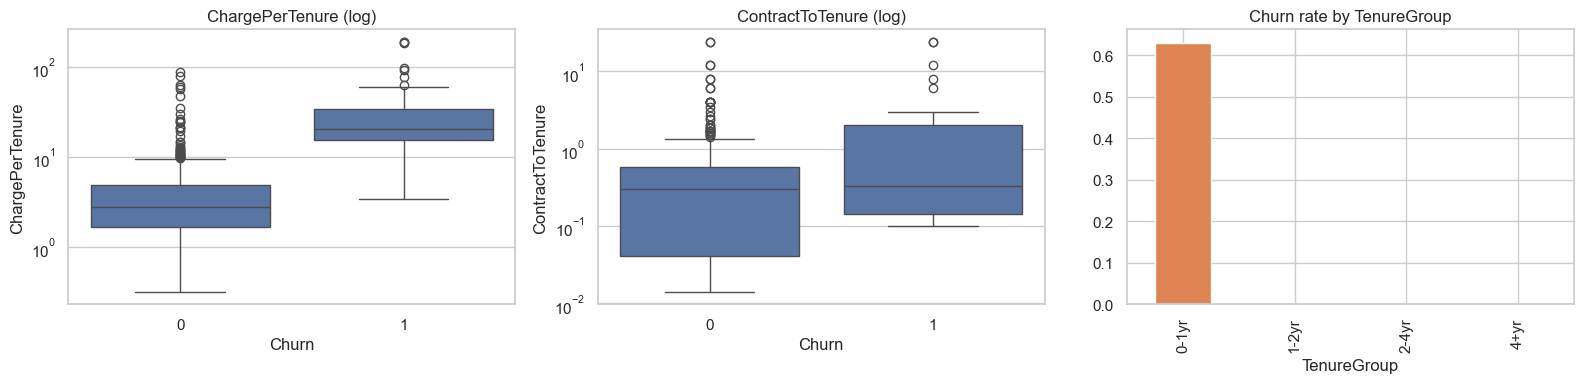

In [21]:
print(df_fe.groupby("TenureGroup")["Churn"].agg(["count", "mean"]).round(3))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.boxplot(x="Churn", y="ChargePerTenure", data=df_fe, ax=axes[0]); axes[0].set_yscale("log")
sns.boxplot(x="Churn", y="ContractToTenure", data=df_fe, ax=axes[1]); axes[1].set_yscale("log")
df_fe.groupby("TenureGroup")["Churn"].mean().reindex(["0-1yr", "1-2yr", "2-4yr", "4+yr"]).plot(kind="bar", ax=axes[2], color="#DD8452")
axes[0].set_title("ChargePerTenure (log)"); axes[1].set_title("ContractToTenure (log)"); axes[2].set_title("Churn rate by TenureGroup")
plt.tight_layout(); plt.savefig("images/06_engineered_features.png", dpi=120); plt.show()

### Feature Selection

In [22]:
# Build a fully numeric matrix for analysis (encodings from Day 2 + new features)
analysis = df_fe.copy()
analysis["PaperlessBilling"] = (analysis["PaperlessBilling"] == "Yes").astype(int)
analysis["Contract"] = analysis["Contract"].map({"Month-to-month": 0, "One year": 1, "Two year": 2})
analysis = pd.get_dummies(analysis, columns=["PaymentMethod", "TenureGroup"], drop_first=True, dtype=int)
X_all = analysis.drop(columns=["CustomerID", "Churn"])
y = analysis["Churn"]
print("Features available:", X_all.shape[1])

Features available: 19


IsNewCustomer                     0.766
ChargePerTenure                   0.518
Tenure                           -0.509
AvgMonthlySpend                   0.405
CLV                              -0.368
TenureGroup_2-4yr                -0.248
TenureGroup_4+yr                 -0.247
PaymentEfficiency                 0.204
Contract                         -0.183
ContractToTenure                  0.176
TenureGroup_1-2yr                -0.145
HighMonthlyCharge                 0.116
MonthlyCharges                    0.107
PaymentMethod_Credit Card         0.070
SeniorCitizen                    -0.018
PaperlessBilling                  0.016
AutoPay                          -0.010
PaymentMethod_Electronic Check    0.010
TotalCharges                      0.004
dtype: float64


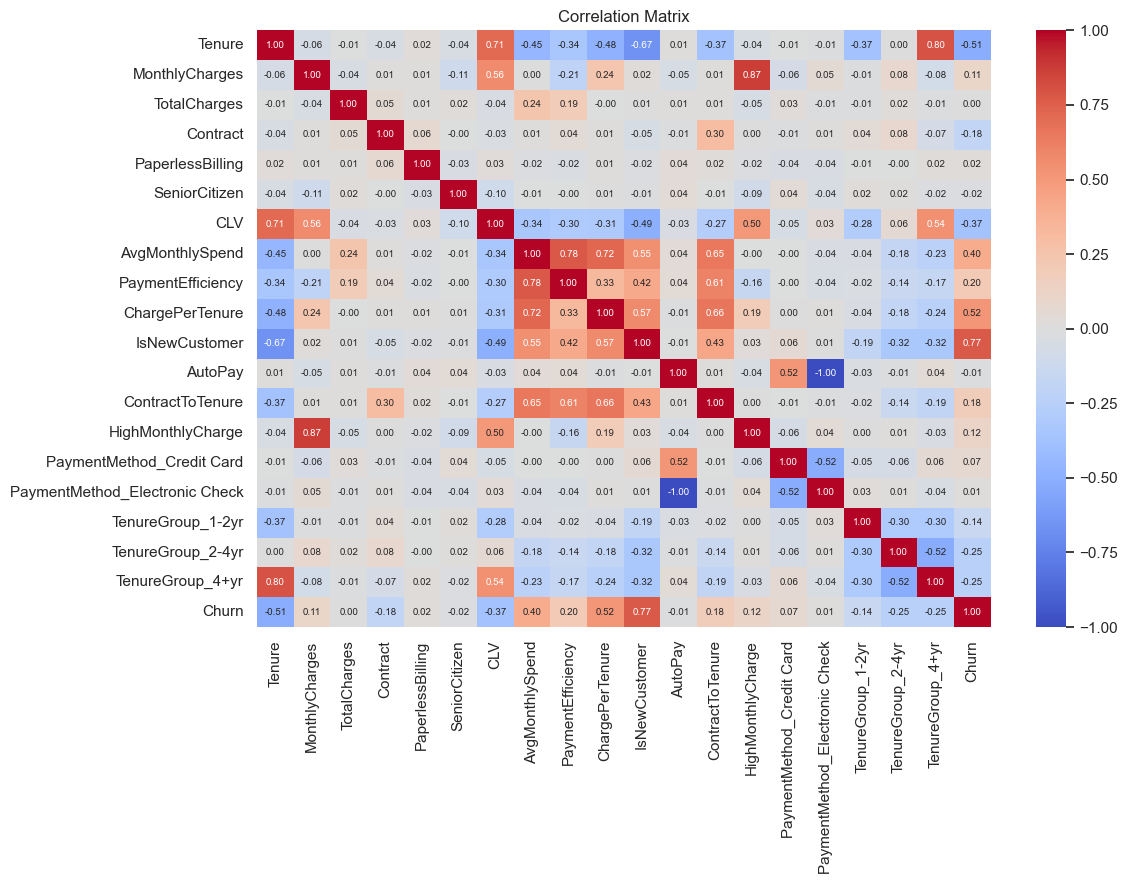

In [23]:
# Method 1: Correlation with target
corr_target = X_all.corrwith(y).sort_values(key=abs, ascending=False)
print(corr_target.round(3))

plt.figure(figsize=(12, 9))
sns.heatmap(pd.concat([X_all, y], axis=1).corr(), cmap="coolwarm", center=0, annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation Matrix"); plt.tight_layout(); plt.savefig("images/07_correlation_heatmap.png", dpi=120); plt.show()

In [24]:
# Check multicollinearity: highly correlated feature pairs (|r| > 0.85)
corr = X_all.corr().abs()
upper = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
high_pairs = upper.stack().loc[lambda s: s > 0.85].sort_values(ascending=False)
print("Highly correlated pairs:\n", high_pairs.round(3) if len(high_pairs) else "None")

Highly correlated pairs:
 AutoPay         PaymentMethod_Electronic Check    1.000
MonthlyCharges  HighMonthlyCharge                 0.871
dtype: float64


In [25]:
# Method 2: Mutual Information (captures non-linear relationships)
mi = pd.Series(mutual_info_classif(X_all, y, random_state=RANDOM_STATE), index=X_all.columns).sort_values(ascending=False)

# Method 3: Random Forest feature importance
rf = RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, class_weight="balanced").fit(X_all, y)
rf_imp = pd.Series(rf.feature_importances_, index=X_all.columns).sort_values(ascending=False)

# Method 4: ANOVA F-test via SelectKBest
skb = SelectKBest(f_classif, k=8).fit(X_all, y)
f_scores = pd.Series(skb.scores_, index=X_all.columns)

selection = pd.DataFrame({"|Correlation|": corr_target.abs(), "MutualInfo": mi,
                          "RF_Importance": rf_imp, "F_score": f_scores}).round(3)
selection["AvgRank"] = selection.rank(ascending=False).mean(axis=1)
selection = selection.sort_values("AvgRank")
selection

,|Correlation|,MutualInfo,RF_Importance,F_score,AvgRank
IsNewCustomer,0.766,0.213,0.174,708.381,1.500
Tenure,0.509,0.220,0.283,174.331,2.000
ChargePerTenure,0.518,0.197,0.172,182.919,2.500
CLV,0.368,0.140,0.114,78.003,4.750
AvgMonthlySpend,0.405,0.115,0.064,97.546,4.750
PaymentEfficiency,0.204,0.086,0.051,21.724,7.250
ContractToTenure,0.176,0.180,0.032,15.877,7.750
TenureGroup_2-4yr,0.248,0.042,0.014,32.706,7.875
TenureGroup_4+yr,0.247,0.042,0.013,32.397,8.625
Contract,0.183,0.018,0.019,17.208,9.750


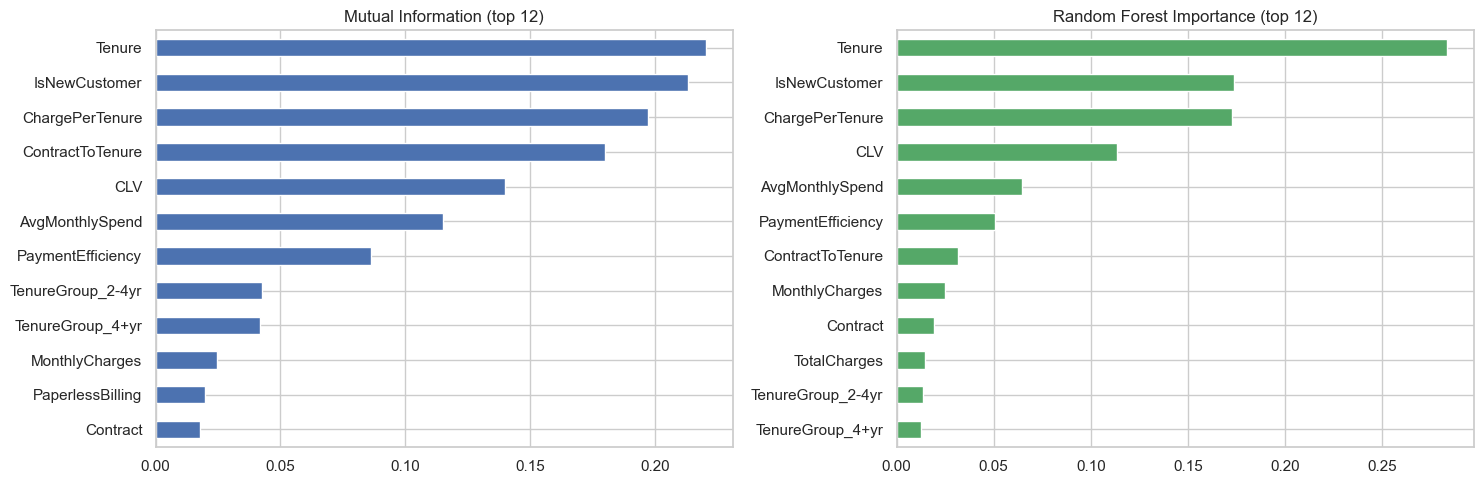

Top 10 features by average rank:
 ['IsNewCustomer', 'Tenure', 'ChargePerTenure', 'CLV', 'AvgMonthlySpend', 'PaymentEfficiency', 'ContractToTenure', 'TenureGroup_2-4yr', 'TenureGroup_4+yr', 'Contract']


In [26]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
mi.head(12).sort_values().plot(kind="barh", ax=axes[0], color="#4C72B0"); axes[0].set_title("Mutual Information (top 12)")
rf_imp.head(12).sort_values().plot(kind="barh", ax=axes[1], color="#55A868"); axes[1].set_title("Random Forest Importance (top 12)")
plt.tight_layout(); plt.savefig("images/08_feature_importance.png", dpi=120); plt.show()

TOP_K = 10
selected_features = selection.head(TOP_K).index.tolist()
print(f"Top {TOP_K} features by average rank:\n", selected_features)

## Preprocessing Pipeline

In [27]:
RAW_FEATURES = ["Tenure", "MonthlyCharges", "TotalCharges", "Contract",
                "PaymentMethod", "PaperlessBilling", "SeniorCitizen"]

RAW_NUM      = ["Tenure", "MonthlyCharges", "TotalCharges"]          # cap outliers + scale
RATIO_NUM    = ["CLV", "AvgMonthlySpend", "PaymentEfficiency",
                "ChargePerTenure", "ContractToTenure"]                # skewed -> log + scale
BIN_FEATURES = ["SeniorCitizen", "IsNewCustomer", "AutoPay", "HighMonthlyCharge"]
ORD_FEATURES = ["Contract"]
NOM_FEATURES = ["PaymentMethod", "TenureGroup"]
LBL_FEATURES = ["PaperlessBilling"]

raw_num_pipe = Pipeline([
    ("cap",   IQRCapper(k=1.5)),            # Day 4: outlier capping
    ("scale", StandardScaler()),            # Day 3: scaling
])
ratio_num_pipe = Pipeline([
    ("log",   FunctionTransformer(np.log1p, feature_names_out="one-to-one")),  # reduce right skew
    ("scale", StandardScaler()),
])

preprocessor = ColumnTransformer([
    ("raw", raw_num_pipe, RAW_NUM),
    ("ratio", ratio_num_pipe, RATIO_NUM),
    ("bin", "passthrough", BIN_FEATURES),
    ("ord", OrdinalEncoder(categories=[["Month-to-month", "One year", "Two year"]]), ORD_FEATURES),
    ("ohe", OneHotEncoder(handle_unknown="ignore", drop="if_binary"), NOM_FEATURES),
    ("lbl", OrdinalEncoder(categories=[["No", "Yes"]]), LBL_FEATURES),   # label-style 0/1
])

def make_pipeline(model):
    return Pipeline([
        ("features", FeatureEngineer()),    # Day 5
        ("preprocess", preprocessor),       # Days 2-4
        ("model", model),
    ])

X = df[RAW_FEATURES]
y = df["Churn"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, stratify=y, random_state=RANDOM_STATE)
print("Train:", X_train.shape, "Test:", X_test.shape, "| churn rate train/test:",
      round(y_train.mean(), 3), "/", round(y_test.mean(), 3))

Train: (375, 7) Test: (125, 7) | churn rate train/test: 0.107 / 0.104


In [28]:
# Compare two models with 5-fold stratified CV on the training set
models = {
    "LogisticRegression": LogisticRegression(max_iter=2000, class_weight="balanced"),
    "RandomForest": RandomForestClassifier(n_estimators=300, max_depth=6, class_weight="balanced",
                                           random_state=RANDOM_STATE),
}
cv_results = {}
for name, m in models.items():
    scores = cross_val_score(make_pipeline(m), X_train, y_train, cv=cv, scoring="roc_auc")
    cv_results[name] = scores
    print(f"{name:<20} CV ROC-AUC = {scores.mean():.3f} ± {scores.std():.3f}")

best_name = max(cv_results, key=lambda k: cv_results[k].mean())
print("\nBest model:", best_name)

LogisticRegression   CV ROC-AUC = 0.987 ± 0.002
RandomForest         CV ROC-AUC = 0.993 ± 0.004

Best model: RandomForest


              precision    recall  f1-score   support

      Stayed       1.00      1.00      1.00       112
     Churned       1.00      1.00      1.00        13

    accuracy                           1.00       125
   macro avg       1.00      1.00      1.00       125
weighted avg       1.00      1.00      1.00       125

Test ROC-AUC: 1.0


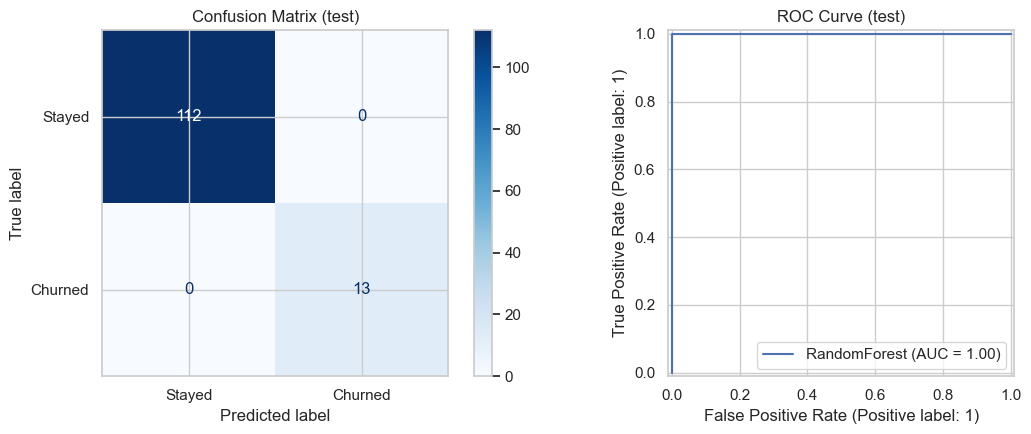

In [29]:
# Fit best pipeline on full training set and evaluate on the held-out test set
final_pipeline = make_pipeline(models[best_name]).fit(X_train, y_train)
y_pred = final_pipeline.predict(X_test)
y_proba = final_pipeline.predict_proba(X_test)[:, 1]

print(classification_report(y_test, y_pred, target_names=["Stayed", "Churned"]))
print("Test ROC-AUC:", round(roc_auc_score(y_test, y_proba), 3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, display_labels=["Stayed", "Churned"], ax=axes[0], cmap="Blues")
RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=best_name)
axes[0].set_title("Confusion Matrix (test)"); axes[1].set_title("ROC Curve (test)")
plt.tight_layout(); plt.savefig("images/09_model_evaluation.png", dpi=120); plt.show()

In [30]:
# Inspect what the preprocessing pipeline outputs (final feature names + shape)
feature_names = final_pipeline.named_steps["preprocess"].get_feature_names_out()
transformed = final_pipeline[:-1].transform(X_test)
print("Pipeline output shape:", transformed.shape)
pd.DataFrame(transformed, columns=feature_names).head()

Pipeline output shape: (125, 21)


,raw__Tenure,raw__MonthlyCharges,raw__TotalCharges,ratio__CLV,ratio__AvgMonthlySpend,ratio__PaymentEfficiency,ratio__ChargePerTenure,ratio__ContractToTenure,bin__SeniorCitizen,bin__IsNewCustomer,...,bin__HighMonthlyCharge,ord__Contract,ohe__PaymentMethod_Bank Transfer,ohe__PaymentMethod_Credit Card,ohe__PaymentMethod_Electronic Check,ohe__TenureGroup_0-1yr,ohe__TenureGroup_1-2yr,ohe__TenureGroup_2-4yr,ohe__TenureGroup_4+yr,lbl__PaperlessBilling
0,1.624185,1.037116,-0.836005,1.391277,-1.092065,-1.035881,-0.455731,-0.490088,0.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0
1,1.672516,0.454496,0.873641,1.217622,-0.306049,-0.640533,-0.614612,-0.793161,0.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,0.029256,0.920592,-0.233018,0.750105,-0.189322,-0.650625,0.049850,-0.766513,1.0,0.0,...,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0
3,-0.792373,-0.011601,-1.334800,-0.169329,-0.588301,-0.711196,0.292073,0.165023,0.0,0.0,...,1.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0
4,-0.260731,0.881750,0.420070,0.569971,0.236670,-0.351185,0.199668,-0.135009,1.0,0.0,...,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0


### Testing & Validation

In [31]:
# Test 1: pipeline works on raw, unseen customer records end-to-end
new_customers = pd.DataFrame([
    {"Tenure": 2,  "MonthlyCharges": 180, "TotalCharges": 360,  "Contract": "Month-to-month",
     "PaymentMethod": "Electronic Check", "PaperlessBilling": "Yes", "SeniorCitizen": 0},
    {"Tenure": 60, "MonthlyCharges": 60,  "TotalCharges": 3600, "Contract": "Two year",
     "PaymentMethod": "Bank Transfer", "PaperlessBilling": "No", "SeniorCitizen": 1},
])
new_customers["ChurnProbability"] = final_pipeline.predict_proba(new_customers)[:, 1].round(3)
new_customers["Prediction"] = np.where(new_customers["ChurnProbability"] >= 0.5, "Likely to churn", "Likely to stay")
new_customers

,Tenure,MonthlyCharges,TotalCharges,Contract,PaymentMethod,PaperlessBilling,SeniorCitizen,ChurnProbability,Prediction
0,2,180,360,Month-to-month,Electronic Check,Yes,0,0.942,Likely to churn
1,60,60,3600,Two year,Bank Transfer,No,1,0.000,Likely to stay


In [32]:
# Test 2: automated checks (assertions) — all must pass
Xt = final_pipeline[:-1].transform(X_test)
assert not np.isnan(Xt).any(), "NaNs in pipeline output"
assert Xt.shape[0] == len(X_test), "Row count changed"

# unseen category -> handled (OneHotEncoder handle_unknown='ignore')
odd = X_test.head(1).copy(); odd["PaymentMethod"] = "Crypto"
_ = final_pipeline.predict(odd)

# extreme value -> capped, still predicts
extreme = X_test.head(1).copy(); extreme["MonthlyCharges"] = 10_000
_ = final_pipeline.predict(extreme)

# tenure = 0 edge case -> no divide-by-zero
zero_t = X_test.head(1).copy(); zero_t["Tenure"] = 0
assert np.isfinite(final_pipeline[:-1].transform(zero_t)).all()

# predictions are probabilities
assert ((y_proba >= 0) & (y_proba <= 1)).all()

# sanity: new short-tenure M2M customer should be riskier than long-tenure 2-year customer
assert new_customers.loc[0, "ChurnProbability"] > new_customers.loc[1, "ChurnProbability"]
print("All pipeline tests passed ✅")

All pipeline tests passed ✅


In [33]:
# Save the trained pipeline and reload it to verify persistence
joblib.dump(final_pipeline, "churn_pipeline.joblib")
reloaded = joblib.load("churn_pipeline.joblib")
assert (reloaded.predict(X_test) == y_pred).all()
print("Pipeline saved to churn_pipeline.joblib and reloaded successfully")

Pipeline saved to churn_pipeline.joblib and reloaded successfully


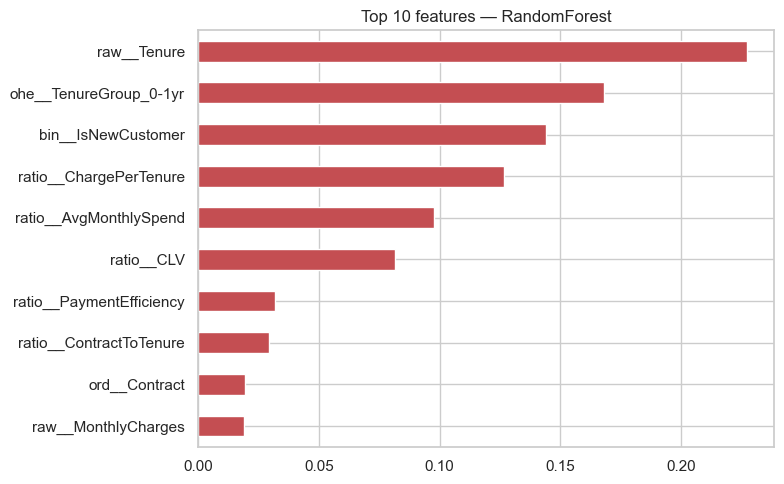

raw__Tenure                 0.227
ohe__TenureGroup_0-1yr      0.168
bin__IsNewCustomer          0.144
ratio__ChargePerTenure      0.127
ratio__AvgMonthlySpend      0.098
ratio__CLV                  0.082
ratio__PaymentEfficiency    0.032
ratio__ContractToTenure     0.029
ord__Contract               0.020
raw__MonthlyCharges         0.019
dtype: float64

In [34]:
# Model-level feature importance from the final pipeline
model = final_pipeline.named_steps["model"]
imp = model.feature_importances_ if hasattr(model, "feature_importances_") else np.abs(model.coef_[0])
final_imp = pd.Series(imp, index=feature_names).sort_values(ascending=False)
final_imp.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#C44E52", title=f"Top 10 features — {best_name}")
plt.tight_layout(); plt.savefig("images/10_final_model_importance.png", dpi=120); plt.show()
final_imp.head(10).round(3)